# EDA Overview:


Data Overview:

In [52]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", 100)

PROJECT_ROOT = Path.cwd().parent
DATA_PATH = PROJECT_ROOT / 'data' / 'raw' / 'listings.csv'

df = pd.read_csv(DATA_PATH)
df = df.dropna(subset=['price'])

all_missing = df.columns[df.isna().all()].tolist()
df_eda = df.drop(columns=all_missing).copy()

df_eda['price'] = pd.to_numeric(df_eda["price"].astype(str).str.replace(r"[$,]", "", regex=True), errors="coerce")
df_eda['price'] = df_eda['price'].astype(float)

display(f"Dataset shape: {df_eda.shape[0]} rows × {df_eda.shape[1]} columns")
display(df_eda.head())

'Dataset shape: 2728 rows × 77 columns'

,id,listing_url,scrape_id,last_scraped,source,name,description,picture_url,host_id,host_url,host_profile_id,host_profile_url,host_name,hosts_time_as_user_years,hosts_time_as_user_months,hosts_time_as_host_years,hosts_time_as_host_months,host_location,host_about,host_is_superhost,host_picture_url,host_listings_count,host_has_profile_pic,host_identity_verified,neighbourhood_cleansed,neighbourhood_group_cleansed,latitude,longitude,property_type,room_type,accommodates,bathrooms_text,bedrooms,beds,amenities,price,price_quote_checkin_date,price_quote_checkout_date,price_quote_total_price,price_quote_price_per_night,price_quote_raw,minimum_nights,maximum_nights,minimum_minimum_nights,maximum_minimum_nights,minimum_maximum_nights,maximum_maximum_nights,minimum_nights_avg_ntm,maximum_nights_avg_ntm,has_availability,availability_30,availability_60,availability_90,availability_365,calendar_last_scraped,number_of_reviews,number_of_reviews_ltm,number_of_reviews_l30d,availability_eoy,number_of_reviews_ly,estimated_occupancy_l365d,estimated_revenue_l365d,first_review,last_review,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,license,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
3,294281,https://www.airbnb.com/rooms/294281,20260923225116,2026-09-26,previous scrape,5 mins walk from Newton subway,I have 3 bedrooms in a charming British style townhouse for you and your family while you are v...,https://a0.muscache.com/pictures/4607862/87f42d40_original.jpg,1521514,https://www.airbnb.com/users/show/1521514,1462518637211194506,https://www.airbnb.com/users/profile/1462518637211194506,Elizbeth,14,9,14,9,Singapore,Hello !\r\nI am Elizabeth from Singapore.\r\n\r\nLooking forward to hosting you in our lovely li...,f,https://a0.muscache.com/im/users/1521514/profile_pic/1324398791/original.jpg?aki_policy=profile_...,7,t,t,Newton,Central Region,1.31142,103.83924,Private room in rental unit,Private room,2,1 shared bath,2.0,1.0,"[""Refrigerator"", ""Kitchen"", ""Smoke alarm"", ""Washer"", ""Wifi"", ""Oven"", ""Air conditioning"", ""Stove""...",86.63,2026-09-26,2026-12-27,7969.93,86.63,"{""quote"": {""taxes"": null, ""currency"": ""SGD"", ""date_match"": null, ""service_fee"": null, ""total_pri...",92.0,1125.0,92.0,92.0,1125.0,1125.0,92.0,1125.0,t,30,60,90,365,2026-09-26,131,0,0,97,0,0,0.0,2012-01-28,2020-01-21,4.43,4.33,4.16,4.50,4.66,4.52,4.39,NaN,7,1,6,0,0.73
4,344803,https://www.airbnb.com/rooms/344803,20260923225116,2026-09-26,previous scrape,Budget short stay room near EXPO,"Direct bus 24 from airport to this place.Walking distance to expo,downtown line3 and east west l...",https://a0.muscache.com/pictures/4240c88e-4dc2-4204-bc2d-a44d9c4cf4b2.jpg,367042,https://www.airbnb.com/users/show/367042,1462516725725391209,https://www.airbnb.com/users/profile/1462516725725391209,Belinda,15,7,15,7,Singapore,"Hi My name is Belinda -Housekeeper \n\nI would like to welcome you to my ""Homestay Website"" \n\n...",f,https://a0.muscache.com/im/users/367042/profile_pic/1382521511/original.jpg?aki_policy=profile_x...,6,t,t,Tampines,East Region,1.34917,103.96090,Private room in home,Private room,1,1.5 shared baths,1.0,1.0,"[""Refrigerator"", ""Kitchen"", ""Paid parking off premises"", ""Lock on bedroom door"", ""AC - split typ...",44.26,2026-09-26,2026-12-27,4072.04,44.26,"{""quote"": {""taxes"": null, ""currency"": ""SGD"", ""date_match"": null, ""service_fee"": null, ""total_pri...",92.0,1125.0,92.0,92.0,1125.0,1125.0,92.0,1125.0,t,30,60,90,365,2026-09-26,60,0,0,97,0,0,0.0,2012-03-13,2023-08-01,4.60,4.59,4.46,4.76,4.58,4.66,4.44,NaN,5,0,5,0,0.34
5,369141,https://www.airbnb.com/rooms/369141,20260923225116,2026-09-26,previous scrape,5mins from Newton Train Station,A room in a charming British style townhouse for you and your

In [53]:
df_eda.info()

<class 'pandas.DataFrame'>
Index: 2728 entries, 3 to 3207
Data columns (total 77 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   id                                            2728 non-null   int64  
 1   listing_url                                   2728 non-null   str    
 2   scrape_id                                     2728 non-null   int64  
 3   last_scraped                                  2728 non-null   str    
 4   source                                        1275 non-null   str    
 5   name                                          2728 non-null   str    
 6   description                                   2715 non-null   str    
 7   picture_url                                   2728 non-null   str    
 8   host_id                                       2728 non-null   int64  
 9   host_url                                      2728 non-null   str    
 10  host

In [54]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
id,2728.0,8.056429e+17,6.473631e+17,2.942810e+05,4.129295e+07,9.987900e+17,1.394673e+18,1.776730e+18
scrape_id,2728.0,2.026092e+13,0.000000e+00,2.026092e+13,2.026092e+13,2.026092e+13,2.026092e+13,2.026092e+13
neighborhood_overview,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
host_id,2728.0,2.326465e+16,1.984502e+17,2.182320e+05,3.470734e+07,1.386492e+08,4.574788e+08,1.759948e+18
host_profile_id,2728.0,1.475309e+18,3.815696e+16,1.462513e+18,1.462959e+18,1.466758e+18,1.469890e+18,1.759948e+18
host_since,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
hosts_time_as_user_years,2728.0,7.601906e+00,4.237437e+00,0.000000e+00,4.000000e+00,9.000000e+00,1.100000e+01,1.600000e+01
hosts_time_as_user_months,2728.0,5.975440e+00,3.517016e+00,0.000000e+00,3.000000e+00,6.000000e+00,9.000000e+00,1.100000e+01
hosts_time_as_host_years,2728.0,7.052786e+00,4.210208e+00,0.000000e+00,3.000000e+00,8.000000e+00,1.000000e+01,1.500000e+01
hosts_time_as_host_months,2728.0,6.129032e+00,3.448643e+00,0.000000e+00,3.000000e+00,6.000000e+00,1.000000e+01,1.100000e+01


Data Quality:

In [55]:
missing_summary = pd.DataFrame({
    "missing_count": df_eda.isna().sum(),
    "missing_percentage": df_eda.isna().mean() * 100,
    "dtype": df_eda.dtypes.astype(str)
})

missing_summary = (
    missing_summary[missing_summary["missing_count"] > 0]
    .sort_values("missing_percentage", ascending=False)
)

display(missing_summary)

print("Duplicate rows:", df.duplicated().sum())

,missing_count,missing_percentage,dtype
source,1453,53.262463,str
review_scores_value,1156,42.375367,float64
reviews_per_month,1156,42.375367,float64
review_scores_accuracy,1156,42.375367,float64
review_scores_cleanliness,1156,42.375367,float64
review_scores_checkin,1156,42.375367,float64
review_scores_communication,1156,42.375367,float64
review_scores_location,1156,42.375367,float64
first_review,1156,42.375367,str
review_scores_rating,1156,42.375367,float64


Duplicate rows: 0


Target Variable Analysis (Price)

In [56]:
display(
    df_eda[[
        "price",
        "price_quote_price_per_night",
        "price_quote_total_price",
        "price_quote_checkin_date",
        "price_quote_checkout_date"
    ]].head(20)
)

,price,price_quote_price_per_night,price_quote_total_price,price_quote_checkin_date,price_quote_checkout_date
3,86.63,86.63,7969.93,2026-09-26,2026-12-27
4,44.26,44.26,4072.04,2026-09-26,2026-12-27
5,80.86,80.86,7438.72,2026-09-26,2026-12-27
6,74.51,74.51,6855.10,2026-09-26,2026-12-27
8,48.53,48.53,4464.39,2026-09-26,2026-12-27
10,143.92,143.92,13241.04,2026-10-03,2027-01-03
11,136.48,136.48,12556.19,2026-09-26,2026-12-27
13,42.05,42.05,3868.45,2026-10-01,2027-01-01
17,67.35,67.35,6195.99,2026-10-01,2027-01-01
18,223.51,223.51,20562.80,2026-10-03,2027-01-03


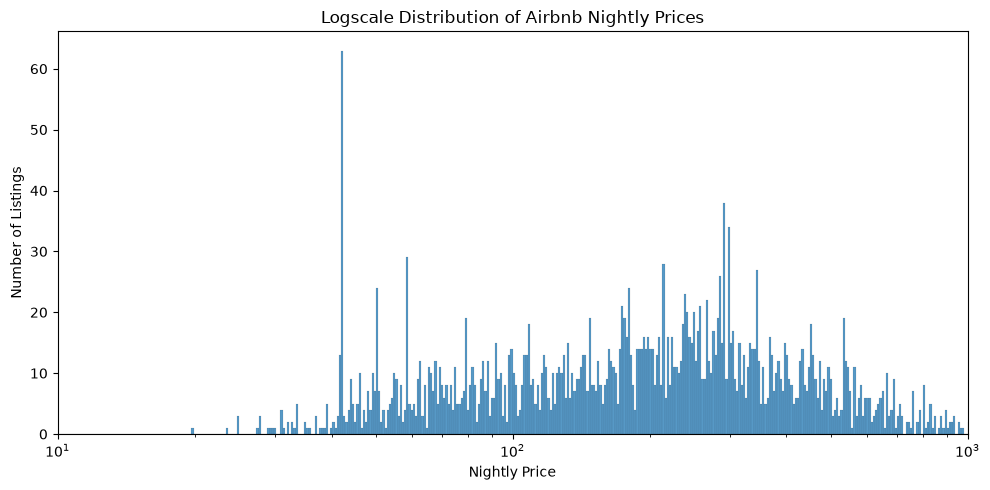

In [57]:
plt.figure(figsize=(10, 5))

sns.histplot(data=df_eda, x="price", bins=1000, log_scale=True)

plt.title("Logscale Distribution of Airbnb Nightly Prices")
plt.xlabel("Nightly Price")
plt.ylabel("Number of Listings")
plt.xlim(10, 1000)
plt.tight_layout()
plt.show()

In [58]:
display(df_eda["price"].describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]))


count     2728.000000
mean       277.327375
std        494.480155
min          0.220000
1%          33.690000
5%          43.963500
25%         99.952500
50%        202.770000
75%        333.077500
95%        678.450500
99%       1244.900000
max      13000.000000
Name: price, dtype: float64

Feature Analysis

hosts_time_as_user_years, (lattitude, longtitude), accomodates, bedrooms, beds, number_of_reviews, review_scores_rating, review_scores_accuracy, review_scores_cleanliness, review_scores_checkin, review_scores_communication, review_scores_location, review_scores_value, calculated_host_listings_count (not sure if relevant), reviews_per_month

mixed: bathrooms_text

host_is_superhost, neighbourhood_cleansed, neighbourhood_group_clensed, amenities

Capacity

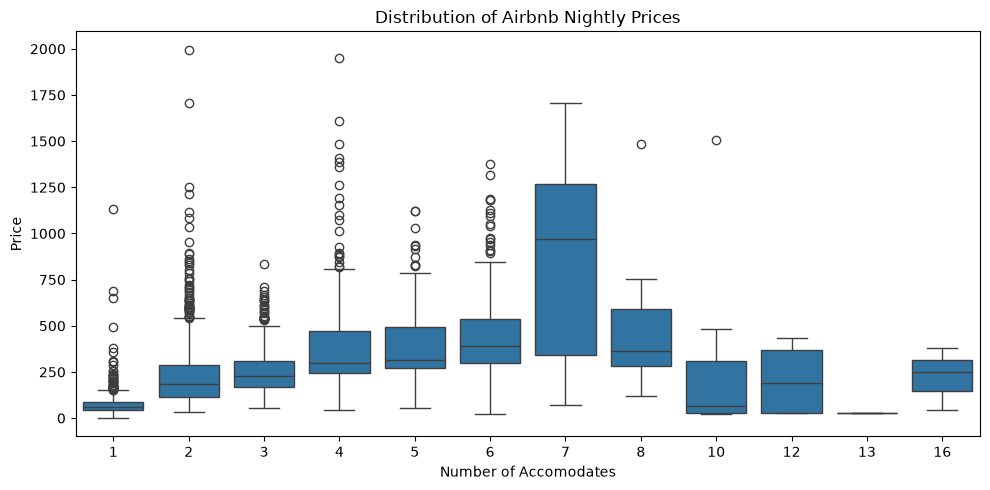

In [59]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df_eda[df_eda['price'] < 2000], x="accommodates", y="price")
plt.title("Distribution of Airbnb Nightly Prices")
plt.xlabel("Number of Accomodates")
plt.ylabel("Price")
plt.tight_layout()
plt.show()

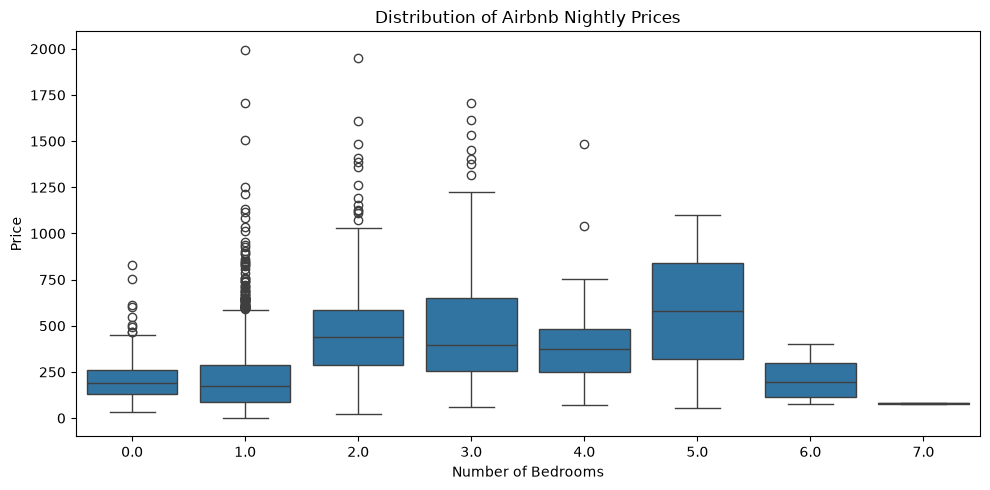

In [60]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df_eda[df_eda['price'] < 2000], x="bedrooms", y="price")
plt.title("Distribution of Airbnb Nightly Prices")
plt.xlabel("Number of Bedrooms")
plt.ylabel("Price")
plt.tight_layout()
plt.show()

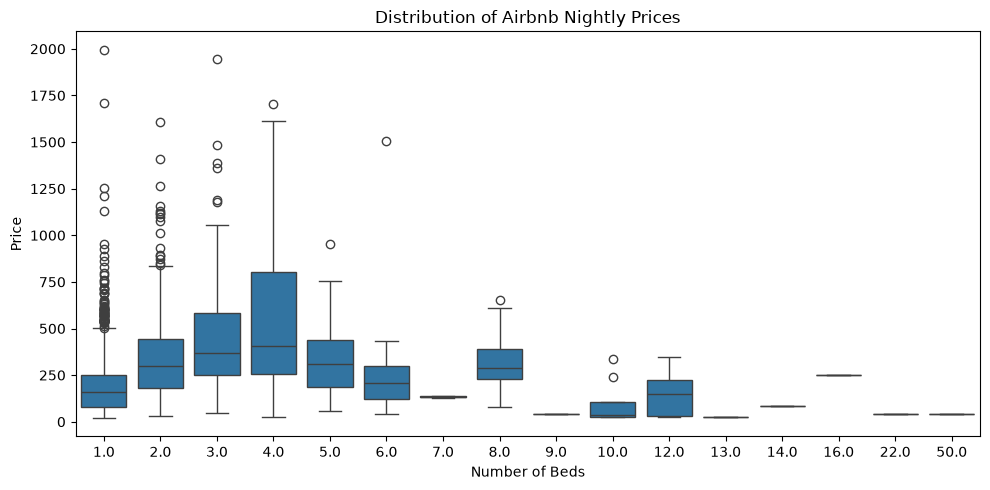

In [61]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df_eda[df_eda['price'] < 2000], x="beds", y="price")
plt.title("Distribution of Airbnb Nightly Prices")
plt.xlabel("Number of Beds")
plt.ylabel("Price")
plt.tight_layout()
plt.show()

Geography

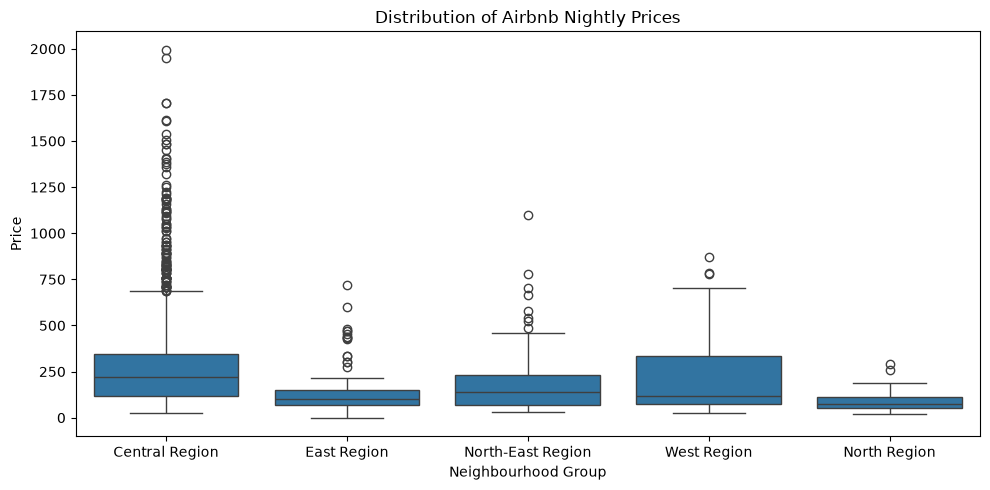

In [62]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df_eda[df_eda['price'] < 2000], x="neighbourhood_group_cleansed", y="price")
plt.title("Distribution of Airbnb Nightly Prices")
plt.xlabel("Neighbourhood Group")
plt.ylabel("Price")
plt.tight_layout()
plt.show()

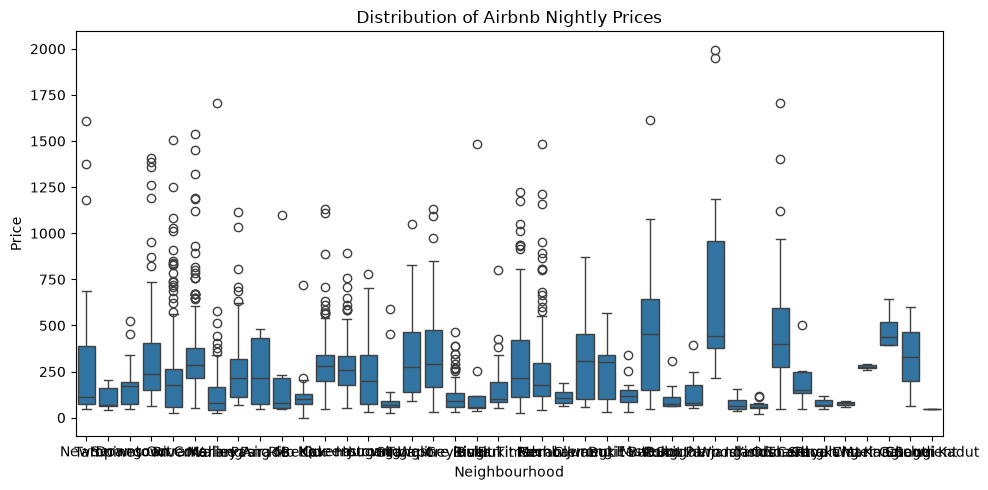

In [63]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df_eda[df_eda['price'] < 2000], x="neighbourhood_cleansed", y="price")
plt.title("Distribution of Airbnb Nightly Prices")
plt.xlabel("Neighbourhood")
plt.ylabel("Price")
plt.tight_layout()
plt.show()

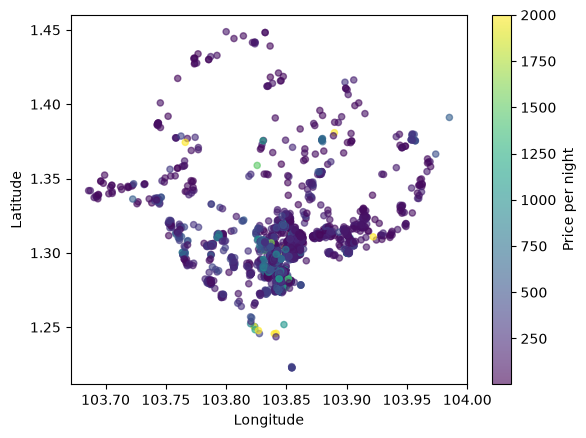

In [64]:
plt.scatter(
    df_eda["longitude"],
    df_eda["latitude"],
    c=df_eda['price'],
    cmap='viridis',
    vmin=1, 
    vmax=2000,
    alpha=0.6,
    s=20
)
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.colorbar(label="Price per night")

Reviews

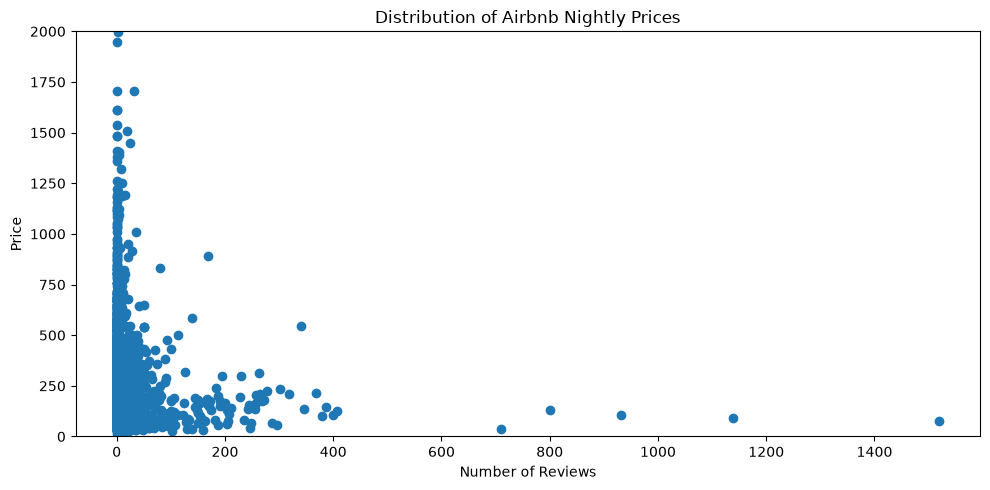

In [65]:
plt.figure(figsize=(10, 5))
plt.scatter(df_eda['number_of_reviews'], df_eda['price'])
plt.ylim(0, 2000)
plt.title("Distribution of Airbnb Nightly Prices")
plt.xlabel("Number of Reviews")
plt.ylabel("Price")
plt.tight_layout()
plt.show()

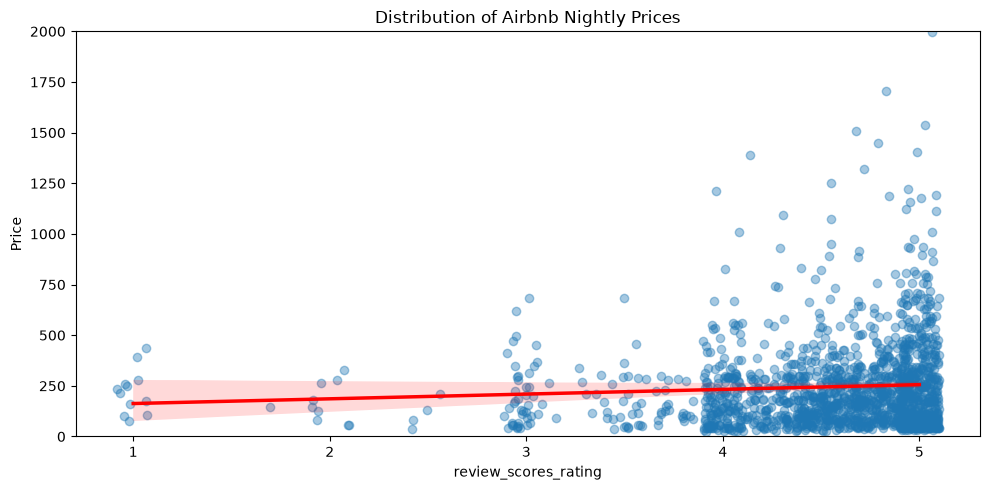

In [66]:
plt.figure(figsize=(10, 5))
sns.regplot(data=df_eda, x='review_scores_rating', y='price', x_jitter=0.1, line_kws={'color': 'red', 'linewidth': 2.5}, scatter_kws={'alpha': 0.4, 'color': '#1f77b4'})
plt.ylim(0, 2000)
plt.title("Distribution of Airbnb Nightly Prices")
plt.xlabel("review_scores_rating")
plt.ylabel("Price")
plt.tight_layout()
plt.show()

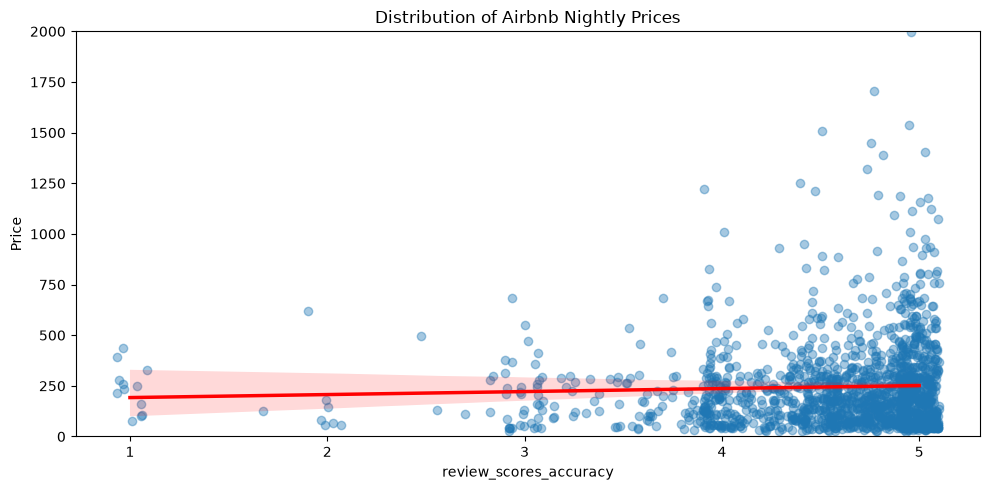

In [67]:
plt.figure(figsize=(10, 5))
sns.regplot(data=df_eda, x='review_scores_accuracy', y='price', x_jitter=0.1, line_kws={'color': 'red', 'linewidth': 2.5}, scatter_kws={'alpha': 0.4, 'color': '#1f77b4'})
plt.ylim(0, 2000)
plt.title("Distribution of Airbnb Nightly Prices")
plt.xlabel("review_scores_accuracy")
plt.ylabel("Price")
plt.tight_layout()
plt.show()

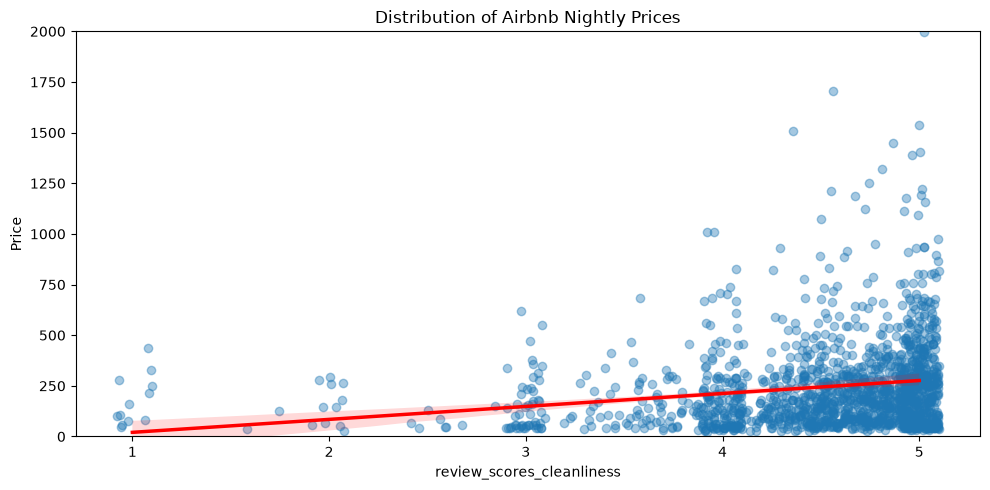

In [68]:
plt.figure(figsize=(10, 5))
sns.regplot(data=df_eda, x='review_scores_cleanliness', y='price', x_jitter=0.1, line_kws={'color': 'red', 'linewidth': 2.5}, scatter_kws={'alpha': 0.4, 'color': '#1f77b4'})
plt.ylim(0, 2000)
plt.title("Distribution of Airbnb Nightly Prices")
plt.xlabel("review_scores_cleanliness")
plt.ylabel("Price")
plt.tight_layout()
plt.show()

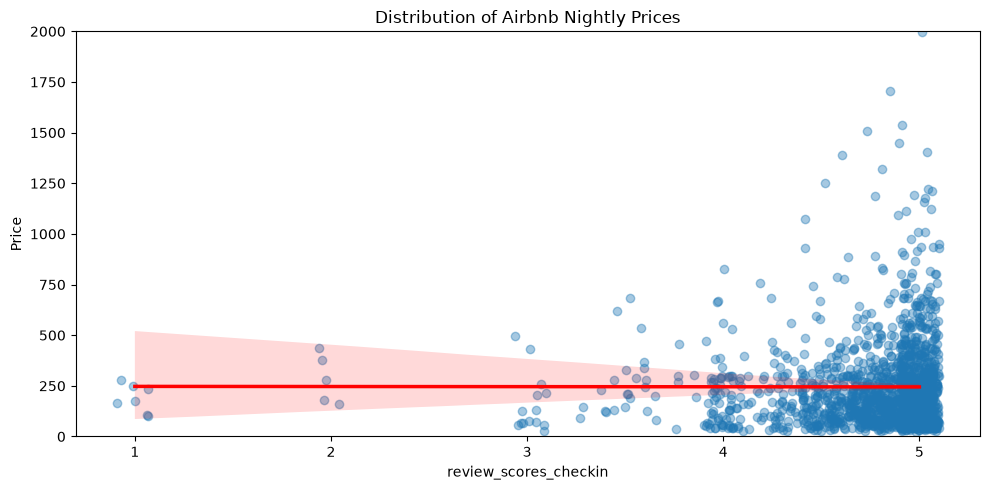

In [69]:
plt.figure(figsize=(10, 5))
sns.regplot(data=df_eda, x='review_scores_checkin', y='price', x_jitter=0.1, line_kws={'color': 'red', 'linewidth': 2.5}, scatter_kws={'alpha': 0.4, 'color': '#1f77b4'})
plt.ylim(0, 2000)
plt.title("Distribution of Airbnb Nightly Prices")
plt.xlabel("review_scores_checkin")
plt.ylabel("Price")
plt.tight_layout()
plt.show()

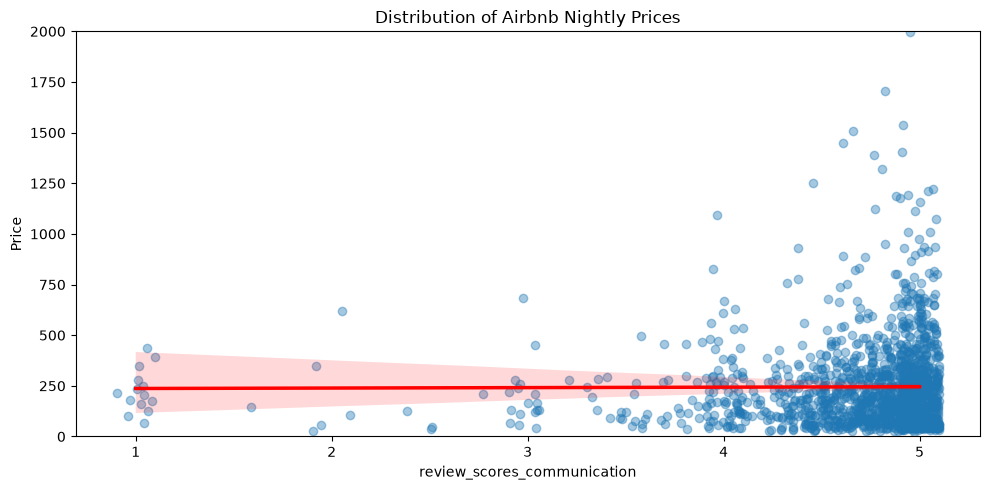

In [70]:
plt.figure(figsize=(10, 5))
sns.regplot(data=df_eda, x='review_scores_communication', y='price', x_jitter=0.1, line_kws={'color': 'red', 'linewidth': 2.5}, scatter_kws={'alpha': 0.4, 'color': '#1f77b4'})
plt.ylim(0, 2000)
plt.title("Distribution of Airbnb Nightly Prices")
plt.xlabel("review_scores_communication")
plt.ylabel("Price")
plt.tight_layout()
plt.show()

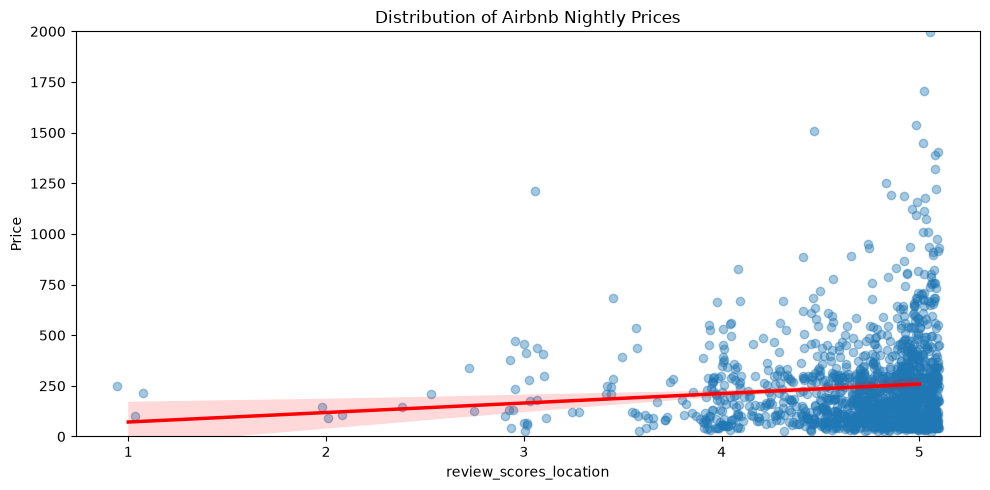

In [71]:
plt.figure(figsize=(10, 5))
sns.regplot(data=df_eda, x='review_scores_location', y='price', x_jitter=0.1, line_kws={'color': 'red', 'linewidth': 2.5}, scatter_kws={'alpha': 0.4, 'color': '#1f77b4'})
plt.ylim(0, 2000)
plt.title("Distribution of Airbnb Nightly Prices")
plt.xlabel("review_scores_location")
plt.ylabel("Price")
plt.tight_layout()
plt.show()

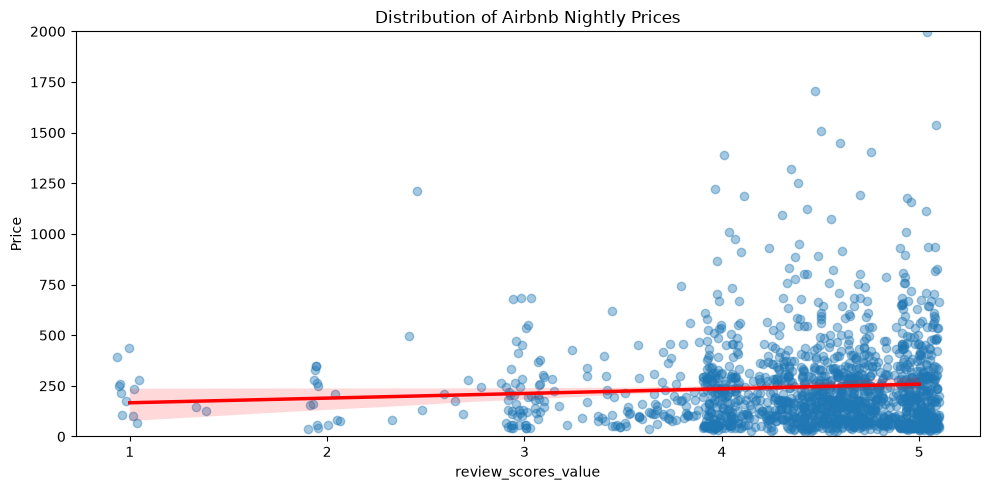

In [72]:
plt.figure(figsize=(10, 5))
sns.regplot(data=df_eda, x='review_scores_value', y='price', x_jitter=0.1, line_kws={'color': 'red', 'linewidth': 2.5}, scatter_kws={'alpha': 0.4, 'color': '#1f77b4'})
plt.ylim(0, 2000)
plt.title("Distribution of Airbnb Nightly Prices")
plt.xlabel("review_scores_value")
plt.ylabel("Price")
plt.tight_layout()
plt.show()

Host characteristics


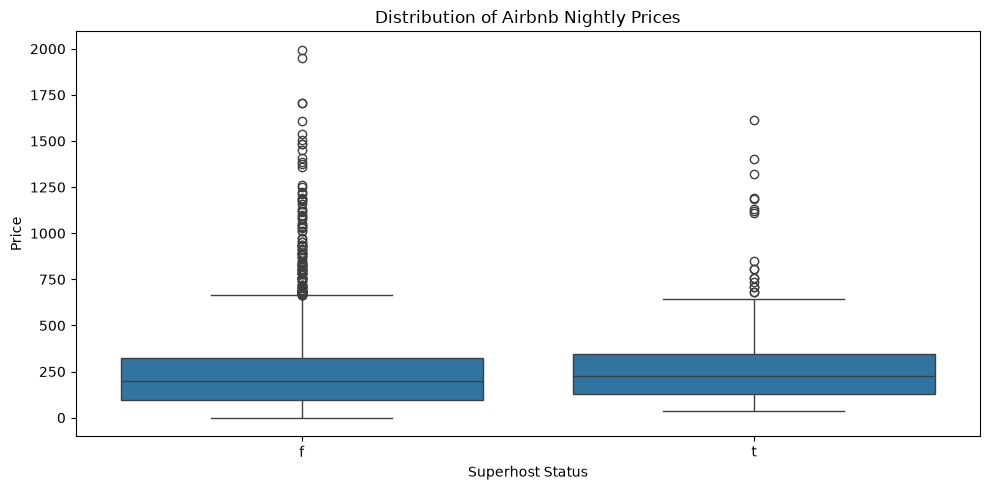

In [73]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df_eda[df_eda['price'] < 2000], x="host_is_superhost", y="price")
plt.title("Distribution of Airbnb Nightly Prices")
plt.xlabel("Superhost Status")
plt.ylabel("Price")
plt.tight_layout()
plt.show()

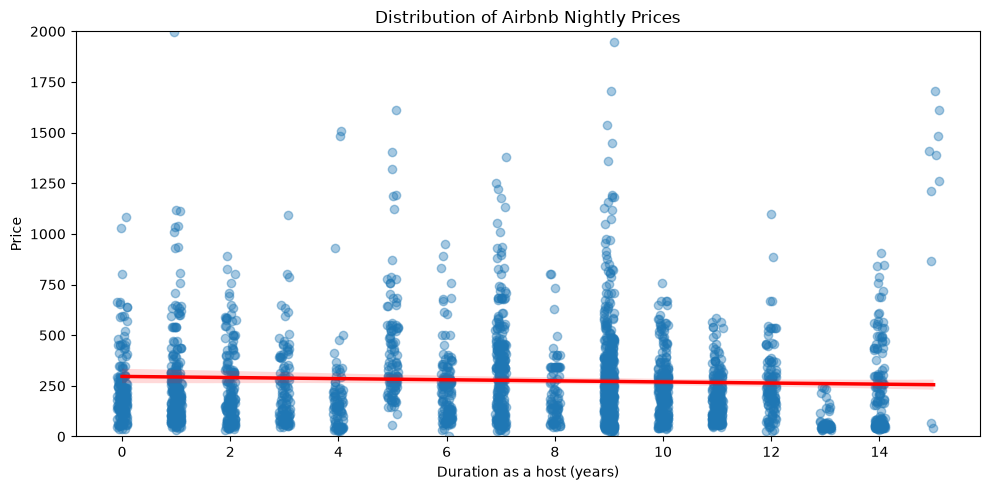

In [74]:
plt.figure(figsize=(10, 5))
sns.regplot(data=df_eda, x='hosts_time_as_host_years', y='price', x_jitter=0.1, line_kws={'color': 'red', 'linewidth': 2.5}, scatter_kws={'alpha': 0.4, 'color': '#1f77b4'})
plt.ylim(0, 2000)
plt.title("Distribution of Airbnb Nightly Prices")
plt.xlabel("Duration as a host (years)")
plt.ylabel("Price")
plt.tight_layout()
plt.show()

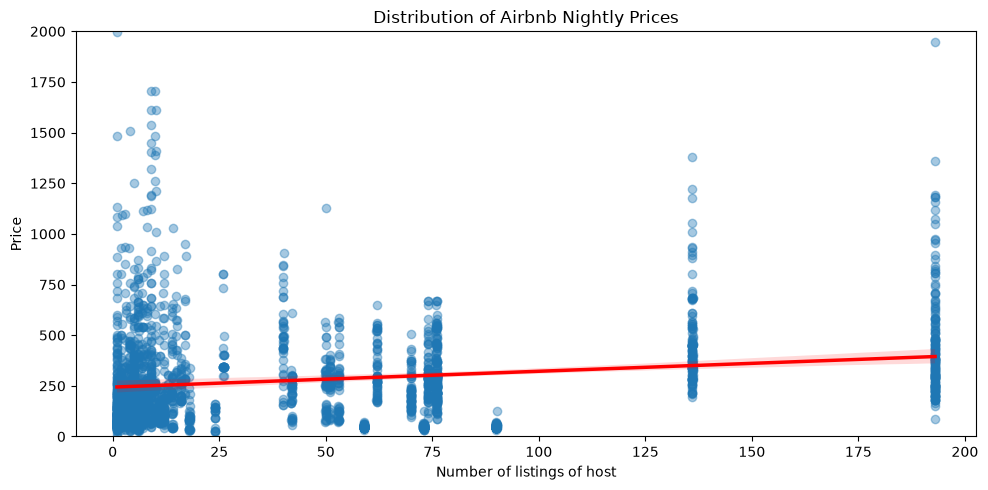

In [75]:
plt.figure(figsize=(10, 5))
sns.regplot(data=df_eda, x='calculated_host_listings_count', y='price', x_jitter=0.1, line_kws={'color': 'red', 'linewidth': 2.5}, scatter_kws={'alpha': 0.4, 'color': '#1f77b4'})
plt.ylim(0, 2000)
plt.title("Distribution of Airbnb Nightly Prices")
plt.xlabel("Number of listings of host")
plt.ylabel("Price")
plt.tight_layout()
plt.show()

Bathrooms


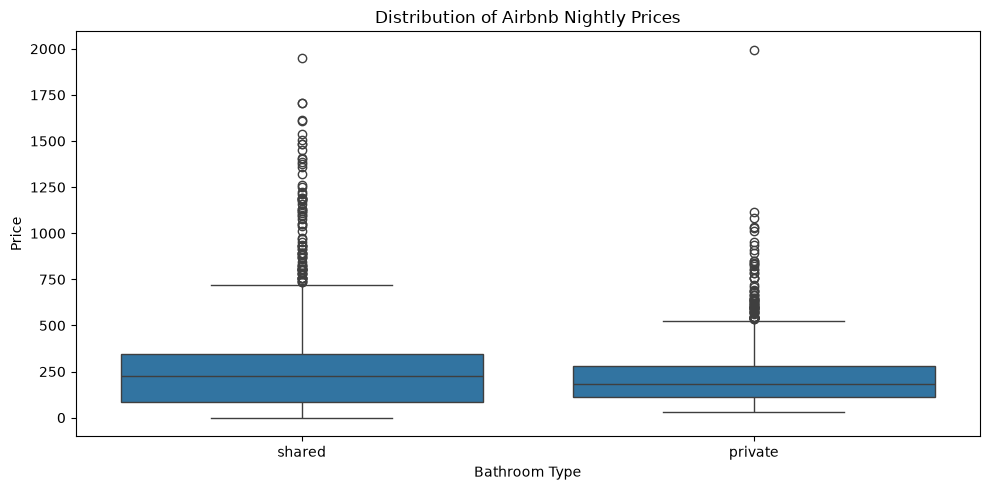

In [76]:
df_eda["bathroom_type"] = np.where(
    df_eda["bathrooms_text"].str.contains("private", case=False, na=False),
    "private",
    "shared"
)

df_eda["bathroom_count"] = np.where(
    df_eda['bathrooms_text'].str.contains("half-bath", case=False, na=False),
    0.5,
    pd.to_numeric(
        df_eda['bathrooms_text'].str.extract(r"(\d+\.?\d*)", expand=False),
        errors="coerce"
    )
)

plt.figure(figsize=(10, 5))
sns.boxplot(data=df_eda[df_eda['price'] < 2000], x="bathroom_type", y="price")
plt.title("Distribution of Airbnb Nightly Prices")
plt.xlabel("Bathroom Type")
plt.ylabel("Price")
plt.tight_layout()
plt.show()


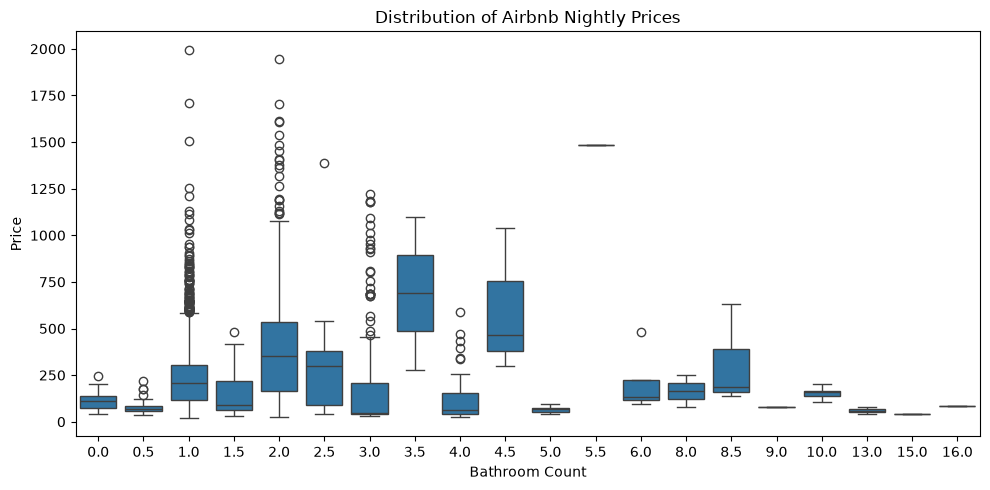

In [77]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df_eda[df_eda['price'] < 2000], x="bathroom_count", y="price")
plt.title("Distribution of Airbnb Nightly Prices")
plt.xlabel("Bathroom Count")
plt.ylabel("Price")
plt.tight_layout()
plt.show()

Amenities

In [78]:
df_eda["amenities"].head()

3    ["Refrigerator", "Kitchen", "Smoke alarm", "Washer", "Wifi", "Oven", "Air conditioning", "Stove"...
4    ["Refrigerator", "Kitchen", "Paid parking off premises", "Lock on bedroom door", "AC - split typ...
5    ["Refrigerator", "Kitchen", "Smoke alarm", "Washer", "Lock on bedroom door", "Wifi", "TV", "Oven...
6    ["Refrigerator", "Kitchen", "Washer", "Wifi", "TV with standard cable", "Oven", "Air conditionin...
8    ["Dryer", "Essentials", "Washer", "Lock on bedroom door", "Air conditioning", "Free parking on p...
Name: amenities, dtype: str

In [79]:
import json
from collections import Counter

amenity_counts = Counter(
    amenity
    for value in df_eda["amenities"].dropna()
    for amenity in json.loads(value)
)

amenity_counts.most_common(20)

[('Wifi', 2641),
 ('Air conditioning', 2570),
 ('Essentials', 2092),
 ('Hot water', 1897),
 ('TV', 1887),
 ('Hair dryer', 1803),
 ('Iron', 1753),
 ('Hangers', 1735),
 ('Kitchen', 1721),
 ('Bed linens', 1699),
 ('Smoke alarm', 1685),
 ('Dedicated workspace', 1650),
 ('Washer', 1627),
 ('Elevator', 1428),
 ('Self check-in', 1422),
 ('Long term stays allowed', 1398),
 ('Luggage dropoff allowed', 1372),
 ('Shampoo', 1283),
 ('Microwave', 1273),
 ('Refrigerator', 1248)]

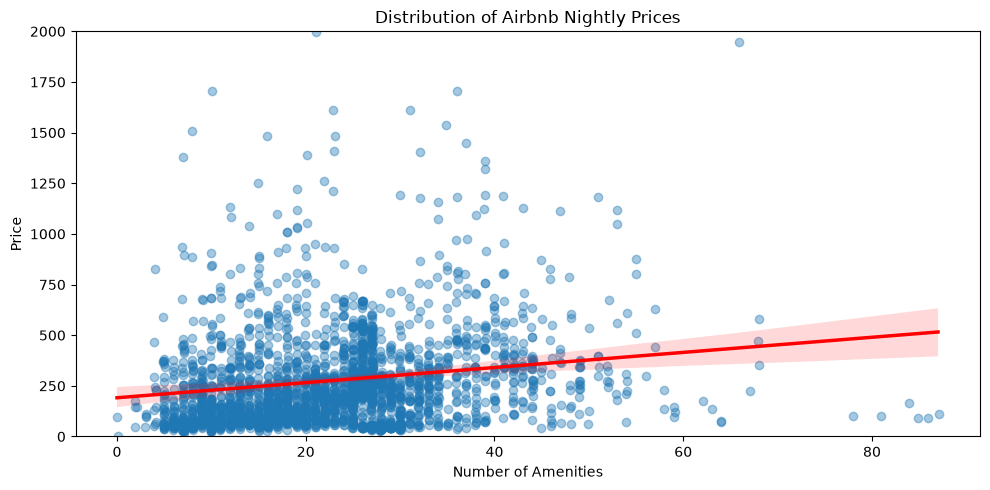

In [80]:
df_eda['amenities_count'] = df_eda['amenities'].apply(lambda x: len(json.loads(x)))

plt.figure(figsize=(10, 5))
sns.regplot(data=df_eda, x='amenities_count', y='price', x_jitter=0.1, line_kws={'color': 'red', 'linewidth': 2.5}, scatter_kws={'alpha': 0.4, 'color': '#1f77b4'})
plt.ylim(0, 2000)
plt.title("Distribution of Airbnb Nightly Prices")
plt.xlabel("Number of Amenities")
plt.ylabel("Price")
plt.tight_layout()
plt.show()

In [87]:
amenity_freq = pd.Series(dict(amenity_counts)).sort_values(ascending=False)

top_40_names = amenity_freq.head(40).index

amenity_summary = []

amenity_lists = df_eda["amenities"].apply(
    lambda x: json.loads(x) if isinstance(x, str) else []
)

for amenity in top_40_names:
    df_eda[f"has_{amenity}"] = amenity_lists.apply(
        lambda listing_amenities: int(amenity in listing_amenities)
    )

for amenity in top_40_names:
    col = f"has_{amenity}"

    grouped = df_eda.groupby(col)["price"]

    median_prices = grouped.median()
    counts = grouped.size()

    amenity_summary.append({
        "amenity": amenity,
        "count_with": counts.get(1, 0),
        "count_without": counts.get(0, 0),
        "median_with": median_prices.get(1, float("nan")),
        "median_without": median_prices.get(0, float("nan")),
        "median_difference": (
            median_prices.get(1, float("nan"))
            - median_prices.get(0, float("nan"))
        )
    })

amenity_summary = pd.DataFrame(amenity_summary)

display(amenity_summary)

,amenity,count_with,count_without,median_with,median_without,median_difference
0,Wifi,2641,87,206.480,147.480,59.000
1,Air conditioning,2570,158,204.000,184.350,19.650
2,Essentials,2092,636,217.690,147.480,70.210
3,Hot water,1897,831,215.670,162.000,53.670
4,TV,1887,841,244.440,100.040,144.400
5,Hair dryer,1803,925,240.000,122.440,117.560
6,Iron,1753,975,227.000,165.140,61.860
7,Hangers,1735,993,215.200,174.940,40.260
8,Kitchen,1721,1007,228.140,182.000,46.140
9,Bed linens,1699,1029,236.980,150.340,86.640


# Conclusion